# 05.7 · Imbalanced data: class weights, resampling, SMOTE, the right metrics

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/07-imbalanced-data/lesson.ipynb)

Read the [README](README.md) first and do the three hand calculations. This notebook:

1. Builds a rare target: ShopWave's top 5% spenders next quarter.
2. Shows accuracy lying, then fixes the model four ways (class weights, over-sampling, under-sampling, SMOTE).
3. Shows the leak you create by resampling before cross-validation.
4. Compares ROC-AUC with PR-AUC, and picks a threshold.

## 1. A rare target

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

# New, rare target: the top 5% of customers by spend in Sep-Nov 2011
threshold_gbp = future_spend.quantile(0.95)
cust["big_spender"] = (future_spend > threshold_gbp).astype(int)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    cust[features], cust["big_spender"], test_size=0.25, random_state=42, stratify=cust["big_spender"])
print(f"big spender = more than £{threshold_gbp:,.0f} next quarter")
print(f"train: {yb_train.sum()} of {len(yb_train):,} ({yb_train.mean():.1%})   "
      f"test: {yb_test.sum()} of {len(yb_test):,} ({yb_test.mean():.1%})")

3,317 customers, churn rate 43.6%, train 2,487 / test 830
big spender = more than £2,393 next quarter
train: 124 of 2,487 (5.0%)   test: 42 of 830 (5.1%)


VIP marketing wants to invite next quarter's biggest spenders to a preview event. Only about 1 customer in 20 qualifies.

## 2. Accuracy lies

In [2]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

def report(name, y_true, proba, t=0.5):
    pred = (proba >= t).astype(int)
    return {"model": name, "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba)}

nobody = np.zeros(len(yb_test))                 # "predict: nobody is a big spender"
pd.DataFrame([report("predict nobody", yb_test, nobody)]).set_index("model").round(3)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,
predict nobody,0.949,0.0,0.0,0.0,0.5,0.051


95% accuracy from a "model" that has learned nothing and finds zero VIPs. On rare targets, accuracy mostly measures how rare the target is.

## 3. A plain model at threshold 0.5

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

LR = lambda **kw: LogisticRegression(max_iter=1000, **kw)
models = {
    "plain":              make_pipeline(StandardScaler(), LR()),
    "class_weight":       make_pipeline(StandardScaler(), LR(class_weight="balanced")),
    "random oversample":  imb_pipeline(StandardScaler(), RandomOverSampler(random_state=42), LR()),
    "random undersample": imb_pipeline(StandardScaler(), RandomUnderSampler(random_state=42), LR()),
    "SMOTE":              imb_pipeline(StandardScaler(), SMOTE(random_state=42), LR()),
}

plain = models["plain"].fit(Xb_train, yb_train)
p_plain = plain.predict_proba(Xb_test)[:, 1]
print(f"customers flagged at 0.5: {(p_plain >= 0.5).sum()} of {len(yb_test)}")
pd.DataFrame([report("plain", yb_test, p_plain)]).set_index("model").round(3)

customers flagged at 0.5: 19 of 830


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,
plain,0.958,0.684,0.31,0.426,0.919,0.525


The model ranks reasonably (look at ROC-AUC) but at the default threshold it is timid: it rarely gets a probability above 0.5 for anyone, because 95% of what it learned from were "no". Recall is low.

## 4. Fix 1: class weights

`class_weight="balanced"` makes each mistake on a rare example cost more in the loss. The weight per class is

$$w_c = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_c}$$

In [4]:
from sklearn.utils.class_weight import compute_class_weight
n, n_pos = len(yb_train), int(yb_train.sum())
print(f"by hand: w_no  = {n} / (2 × {n - n_pos}) = {n / (2 * (n - n_pos)):.3f}")
print(f"by hand: w_yes = {n} / (2 × {n_pos}) = {n / (2 * n_pos):.3f}")
print("sklearn:", compute_class_weight("balanced", classes=np.array([0, 1]), y=yb_train).round(3))

by hand: w_no  = 2487 / (2 × 2363) = 0.526
by hand: w_yes = 2487 / (2 × 124) = 10.028
sklearn: [ 0.526 10.028]


Each big spender now counts as about 10 ordinary customers. Total weight per class is equal: the model can no longer win by ignoring the rare class.

## 5. Fix 2 and 3: random over- and under-sampling

Instead of weighting, change the training rows. **Over-sampling** copies rare rows until classes balance; **under-sampling** throws away common rows. Here are the training-set counts each produces:

In [5]:
Xs = StandardScaler().fit_transform(Xb_train)
for sampler in [RandomOverSampler(random_state=42), RandomUnderSampler(random_state=42), SMOTE(random_state=42)]:
    _, y_res = sampler.fit_resample(Xs, yb_train)
    print(f"{type(sampler).__name__:<20} {np.bincount(yb_train)} → {np.bincount(y_res)}")

RandomOverSampler    [2363  124] → [2363 2363]
RandomUnderSampler   [2363  124] → [124 124]
SMOTE                [2363  124] → [2363 2363]


Under-sampling trains on only about 250 customers: fast, but it throws away 95% of the information.

## 6. Fix 4: SMOTE, drawn

SMOTE creates *new* rare examples instead of copying. For a rare point $x$ it picks one of its nearest rare neighbours $x_{nn}$ and a random $\lambda$ between 0 and 1, then places a new point on the line between them:

$$x_{\text{new}} = x + \lambda\,(x_{nn} - x)$$

The README example, checked:

In [6]:
x, x_nn, lam = np.array([2.0, 3.0]), np.array([4.0, 7.0]), 0.25
print("x_new =", x + lam * (x_nn - x))

x_new = [2.5 4. ]


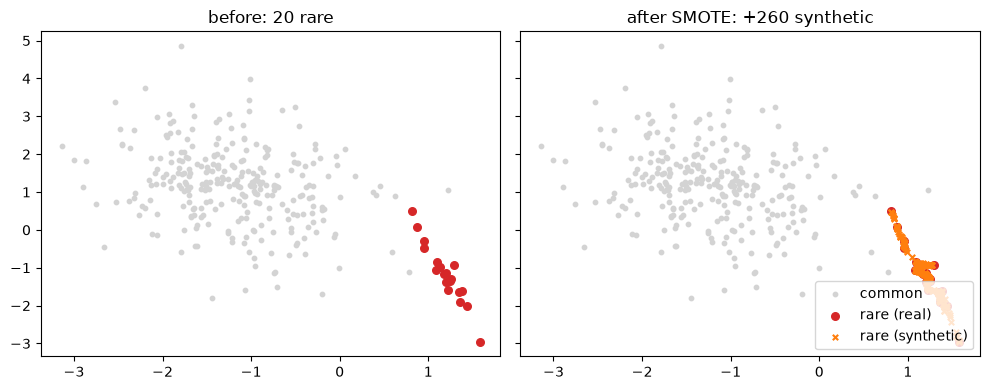

In [7]:
from sklearn.datasets import make_classification
X2, y2 = make_classification(n_samples=300, n_features=2, n_redundant=0, n_clusters_per_class=1,
                             weights=[0.93], class_sep=1.2, random_state=7)
X2s, y2s = SMOTE(random_state=0, k_neighbors=3).fit_resample(X2, y2)
new = X2s[len(X2):]                                      # SMOTE appends the synthetic rows
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, title in [(axes[0], f"before: {y2.sum()} rare"), (axes[1], f"after SMOTE: +{len(new)} synthetic")]:
    ax.scatter(*X2[y2 == 0].T, s=10, c="lightgray", label="common")
    ax.scatter(*X2[y2 == 1].T, s=30, c="tab:red", label="rare (real)"); ax.set_title(title)
axes[1].scatter(*new.T, s=15, c="tab:orange", marker="x", label="rare (synthetic)")
axes[1].legend(loc="lower right"); plt.tight_layout(); plt.show()

The synthetic points fill in the space *between* real rare points. They do not invent new regions.

## 7. The leak: resampling before cross-validation

Resampling must happen **inside** each training fold, never before splitting. If you SMOTE the whole training set and then cross-validate, synthetic points built from a validation customer end up in the training folds, and the model is graded on near-copies of what it studied.

`imblearn.pipeline` handles this correctly: the sampler runs only during `fit`, so validation folds stay untouched. Compare:

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

X_sm, y_sm = SMOTE(random_state=42).fit_resample(Xb_train, yb_train)      # WRONG: before CV
wrong = cross_val_score(rf, X_sm, y_sm, cv=cv, scoring="average_precision")
right = cross_val_score(imb_pipeline(SMOTE(random_state=42), rf), Xb_train, yb_train,
                        cv=cv, scoring="average_precision")
print(f"SMOTE before CV (leaky):    PR-AUC {wrong.mean():.3f}")
print(f"SMOTE inside pipeline:      PR-AUC {right.mean():.3f}")

SMOTE before CV (leaky):    PR-AUC 0.992
SMOTE inside pipeline:      PR-AUC 0.579


The leaky version looks spectacular and is meaningless; part of what it scores is SMOTE's own synthetic points. (Its validation folds are also 50% positive, which inflates PR-AUC on its own.) Always resample inside a pipeline.

## 8. Compare all fixes on the test set

In [9]:
rows, probas = [], {}
for name, m in models.items():
    probas[name] = m.fit(Xb_train, yb_train).predict_proba(Xb_test)[:, 1]
    rows.append(report(name, yb_test, probas[name]))
comparison = pd.DataFrame(rows).set_index("model")
comparison.round(3)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,
plain,0.958,0.684,0.310,0.426,0.919,0.525
class_weight,0.901,0.318,0.833,0.461,0.940,0.521
random oversample,0.900,0.315,0.833,0.458,0.946,0.524
random undersample,0.864,0.255,0.881,0.396,0.927,0.542
SMOTE,0.896,0.307,0.833,0.449,0.939,0.500


Read this table column by column:

- **Recall** jumps for every fix, from 0.31 to about 0.83: the rebalanced models flag far more customers.
- **Precision** drops, from 0.68 to about 0.31: most of those flagged are not big spenders.
- **F1** improves only a little (0.43 → about 0.46).
- **ROC-AUC rises slightly and PR-AUC hardly moves.** The fixes did not make the model *rank* customers much better. They mostly moved where the 0.5 cut falls.

That last point leads to the simplest fix of all.

## 9. ROC-AUC vs PR-AUC

A random model scores ROC-AUC 0.5 regardless of class balance. Its PR-AUC equals the **positive rate**, here about 0.05. So the plain model's ROC-AUC of 0.92 sounds near-perfect, while its PR-AUC of 0.53 says "of the customers we flag, typically only about half are VIPs". On rare targets, PR-AUC is the more honest summary.

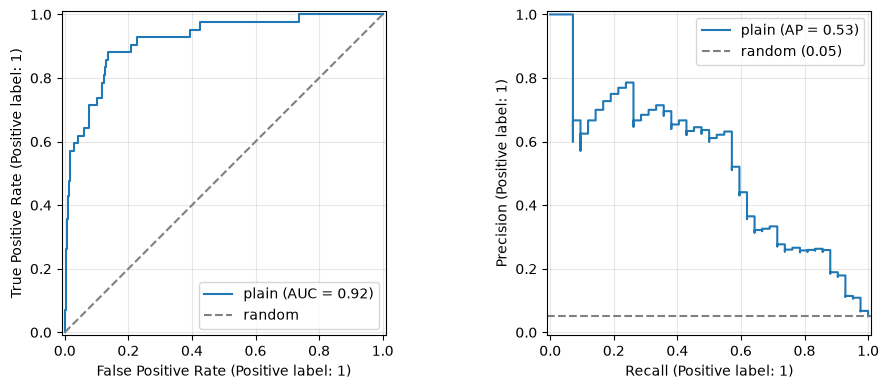

In [10]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(yb_test, probas["plain"], ax=axes[0], name="plain")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="random")
PrecisionRecallDisplay.from_predictions(yb_test, probas["plain"], ax=axes[1], name="plain")
axes[1].axhline(yb_test.mean(), ls="--", color="gray", label=f"random ({yb_test.mean():.2f})")
for ax in axes: ax.legend(loc="best"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 10. Fix 5: just move the threshold

Keep the plain model and choose the threshold that maximises F1, using **cross-validated predictions on the training set** (never the test set). Then apply it to test once.

In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
p_cv = cross_val_predict(models["plain"], Xb_train, yb_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(yb_train, p_cv)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_t = thr[f1.argmax()]
print(f"threshold chosen on training CV: {best_t:.3f}")
pd.DataFrame([report("plain, t=0.5", yb_test, p_plain),
              report(f"plain, t={best_t:.2f}", yb_test, p_plain, t=best_t),
              report("class_weight, t=0.5", yb_test, probas["class_weight"])]).set_index("model").round(3)

threshold chosen on training CV: 0.243


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,
"plain, t=0.5",0.958,0.684,0.310,0.426,0.919,0.525
"plain, t=0.24",0.959,0.611,0.524,0.564,0.919,0.525
"class_weight, t=0.5",0.901,0.318,0.833,0.461,0.940,0.521


A single number, chosen honestly, lifts the plain model's F1 from 0.43 to 0.56, better than any of the rebalancing fixes at 0.5, with precision 0.61 and recall 0.52. Class weights and resampling are useful (especially for models without probabilities, or when training is unstable), but **always try the threshold first**. It is free, and it is a business decision anyway (03.7).

## Quiz answers

1. Because predicting the majority class for everyone scores the majority rate (here 95%) while catching none of the rare cases. Accuracy is dominated by the common class.
2. $w = 1000 / (2 \times 40) = 12.5$ for the rare class and $1000/(2 \times 960) \approx 0.52$ for the common class.
3. $x_{\text{new}} = (1, 1) + 0.5 \times ((3, 5) - (1, 1)) = (2, 3)$.
4. Synthetic points created from a validation-fold customer leak into the training folds (and validation folds become artificially balanced), so the CV score is inflated. Resample inside a pipeline so it only happens on training folds.
5. PR-AUC: its random baseline is the positive rate, so it shows how hard the rare class really is; ROC-AUC can look excellent because true negatives are plentiful.

**Next:** [05.8 Explaining models](../08-explaining-models/)